In [1]:
import simpy  
import numpy as np 
import sys
import pandas as pd 
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.spatial import cKDTree
from shapely.geometry import Point
from utils import generate_incidents
from shapely.affinity import rotate

print(sys.executable)


/Users/adegheosaasoro/Downloads/yes/envs/ems-torch/bin/python


In [2]:
# I am currently trying to upload the points for existing hospitals and populations into facilities and populations variable 
Facilities = gpd.read_file("manhattan-data/manhattan_hospitals_ems.gpkg")

Populations = gpd.read_file("manhattan-data/manhattan_population_blocks.gpkg")

print(Populations)



rows, cols = Facilities.shape

print(f"There exists:{rows} and {cols} columns pertaiing to Facilities")


rowss,colss = Populations.shape

print(f"There exists:{rowss} and {colss} columns pertaining to Populations")



total_population = Populations["POP20"].sum()

print(f"The total population is {total_population}")

asset_type = Facilities["asset_type"]
print(asset_type)
uniquecategories= Facilities["asset_type"].unique()
valuecount= Facilities["asset_type"].value_counts()
missingclassifications= Facilities["asset_type"].isna().sum()

print(f"The unique categories are {uniquecategories}")
print(f"The valuecounts are {valuecount}")
print(f"The missing classifications are {missingclassifications}")

Populationcrs = Populations.crs
Facilitiescrs = Facilities.crs
print(Populationcrs)
print(Facilitiescrs)

popgeometrytype= Populations.geom_type.value_counts()
facgeometrytype = Facilities.geom_type.value_counts()

print(popgeometrytype)
print(facgeometrytype)

missingpopgeometry = Populations["geometry"].isna().sum()
missingfacgeometry = Facilities["geometry"].isna().sum()

print(missingpopgeometry)
print(missingfacgeometry)

emptypopgeometry= Populations["geometry"].is_empty.sum()
emptyfacgeometry= Facilities["geometry"].is_empty.sum()

print(emptypopgeometry)
print(emptyfacgeometry)








    STATEFP20 COUNTYFP20 TRACTCE20 BLOCKCE20          GEOID20      NAME20  \
0          36        061    008603      4009  360610086034009  Block 4009   
1          36        061    008000      6001  360610080006001  Block 6001   
2          36        061    005400      1000  360610054001000  Block 1000   
3          36        061    008900      4000  360610089004000  Block 4000   
4          36        061    008300      1001  360610083001001  Block 1001   
..        ...        ...       ...       ...              ...         ...   
902        36        061    004200      1003  360610042001003  Block 1003   
903        36        061    004400      7001  360610044007001  Block 7001   
904        36        061    009400      1002  360610094001002  Block 1002   
905        36        061    004200      2002  360610042002002  Block 2002   
906        36        061    005800      3002  360610058003002  Block 3002   

    MTFCC20 UR20 UACE20 UATYPE20 FUNCSTAT20  ALAND20  AWATER20   INTPTLAT20

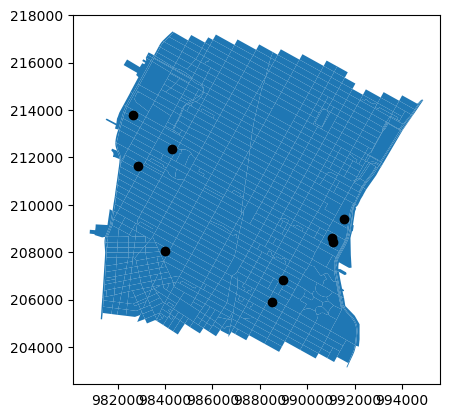

The number of incidents are 348
Index(['day', 'seconds_since_midnight', 'hour', 'minute', 'second',
       'block_index', 'latitude', 'longitude', 'geometry'],
      dtype='object')
The CRS property is EPSG:4326
Geometry types is equals to Point    348
Name: count, dtype: int64
The minimum day is 0
The maximun day is 9
day
0    35
1    43
2    40
3    35
4    30
5    37
6    23
7    25
8    37
9    43
Name: count, dtype: int64
EPSG:32618
EPSG:32618
EPSG:32618
asset_type
EMS station    4
Name: count, dtype: int64
EPSG:32618
asset_type
Hospital    5
Name: count, dtype: int64
EPSG:32618


In [3]:
fig, axs = plt.subplots()
Populations.plot(ax=axs)
Facilities.plot(ax=axs, color = 'black')
plt.show()


incidents = generate_incidents(Populations,
    n_days=10,
    rate_per_1000_per_day=0.1,
    random_seed=42,
                              )

print(f"The number of incidents are {len(incidents)}")
print(incidents.columns)
print(f"The CRS property is {incidents.crs}")
print(f"Geometry types is equals to {incidents.geom_type.value_counts()}")
print(f"The minimum day is {incidents["day"].min()}")
print(f"The maximun day is {incidents["day"].max()}")
print(incidents["day"].value_counts().sort_index())


Populations_m = Populations.to_crs("EPSG:32618")
Facilities_m= Facilities.to_crs("EPSG:32618")
incidents_m = incidents.to_crs("EPSG:32618")

print(Populations_m.crs)
print(Facilities_m.crs)
print(incidents_m.crs)

hospitalmask = Facilities_m["asset_type"] == "Hospital"
Hospitals = Facilities_m[hospitalmask].copy()

emsmask = Facilities_m["asset_type"] == "EMS station"
emsstation = Facilities_m[emsmask].copy()


print(emsstation["asset_type"].value_counts())
print(emsstation.crs)
print(Hospitals["asset_type"].value_counts())
print(Hospitals.crs)








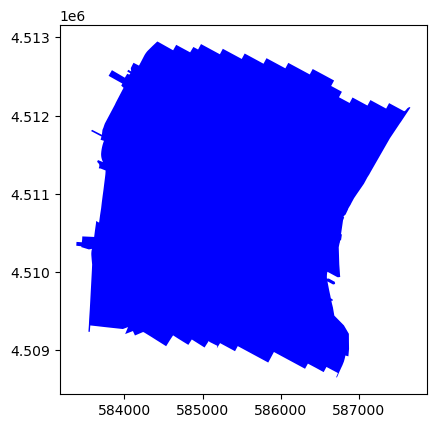

POINT (585350.1984357947 4510879.1243133005)
585350.1984357947
4510879.1243133005
28
582072.1625278692 588822.1625278692
28
4507601.088405375 4514351.088405375


In [4]:
study_area = Populations_m["geometry"].union_all()

min_x, min_y, max_x, max_y = study_area.bounds

geoseries = gpd.GeoSeries([study_area], crs=Populations_m.crs,)

fig, axs = plt.subplots()
geoseries.plot(ax=axs, color = 'blue')
plt.show()

centroidpoint = study_area.centroid
centroidx = centroidpoint.x
centroidy = centroidpoint.y

print(centroidpoint)
print(centroidx)
print(centroidy)

spacing = 250

studyareaheight = max_y - min_y
studyareawidth = max_x - min_x

diagonal = np.hypot(studyareawidth, studyareaheight)
half_span = diagonal / 2 + spacing

start = centroidx - half_span
stop = centroidx + half_span + spacing
step = spacing

starty = centroidy - half_span
stopy = centroidy + half_span + spacing
stepy = spacing


x_coordinates = np.arange(start,stop, step)
y_coordinates = np.arange(starty,stopy, stepy)

print(len(x_coordinates))
print(x_coordinates[0], x_coordinates[-1])

print(len(y_coordinates))
print(y_coordinates[0], y_coordinates[-1])

784
1512
Rotated positions: 784
Nodes removed: 592
Nodes remaining: 192
Edges remaining: 348
Connected sections found: 1
Final nodes: 192
Final edges: 348
Graph is connected: True


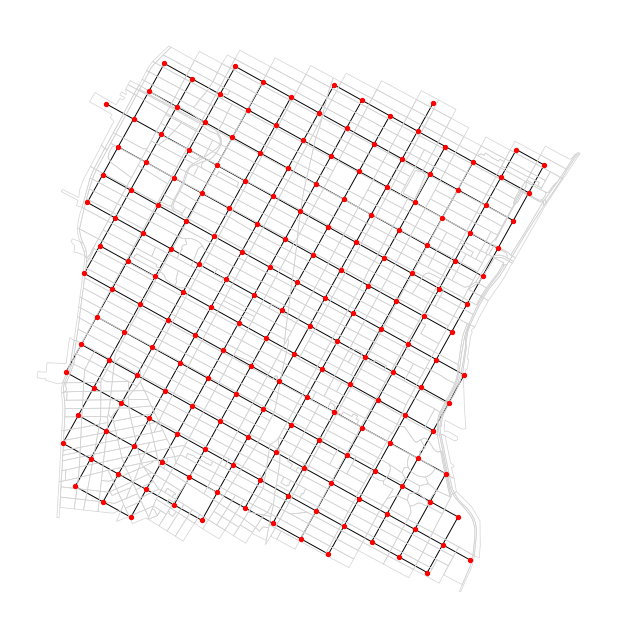

In [5]:
Graph = nx.grid_2d_graph(len(x_coordinates), len(y_coordinates), periodic=False, create_using=None)

print(len(Graph.nodes))
print(len(Graph.edges))


unrotated_positions = {}

for node in Graph.nodes:
    x_index, y_index = node

    x_coordinate = float(x_coordinates[x_index])
    y_coordinate = float(y_coordinates[y_index])

    position = (x_coordinate, y_coordinate)

    unrotated_positions[node] = position

# I am trying to now rotate the graph so it fits the 

grid_rotation_angle = -29

rotation_origin = (
    centroidx,
    centroidy,
)

rotated_positions = {}

for node, coordinates in unrotated_positions.items():
    original_x = coordinates[0]
    original_y = coordinates[1]

    original_point = Point(
        original_x,
        original_y,
    )

    rotated_point = rotate(
        original_point,
        grid_rotation_angle,
        origin=rotation_origin,
        use_radians=False,
    )

    rotated_positions[node] = (
        float(rotated_point.x),
        float(rotated_point.y),
    )

print("Rotated positions:", len(rotated_positions))


# This function is essentially removing the nodes that have been created that fall outside the bounds of the study area that was created 

outside_nodes = [] 

for node, coordinates in rotated_positions.items():
    node_point = Point(coordinates)

    if not study_area.covers(node_point):
        outside_nodes.append(node)

Graph.remove_nodes_from(outside_nodes)

print("Nodes removed:", len(outside_nodes))
print("Nodes remaining:", Graph.number_of_nodes())
print("Edges remaining:", Graph.number_of_edges())

connected_sections = list(nx.connected_components(Graph))

largest_section = max(
    connected_sections,
    key=len,
)

Graph = Graph.subgraph(largest_section).copy()

positions = {}

for node in Graph.nodes:
    positions[node] = rotated_positions[node]

print("Connected sections found:", len(connected_sections))
print("Final nodes:", Graph.number_of_nodes())
print("Final edges:", Graph.number_of_edges())
print("Graph is connected:", nx.is_connected(Graph))

#This code is overlaying the created graph over the Populations graph 

fig, ax = plt.subplots(figsize=(8, 8))

Populations_m.boundary.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5,
)

nx.draw(
    Graph,
    pos=positions,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="black",
    width=0.7,
)

ax.set_aspect("equal")
plt.show()


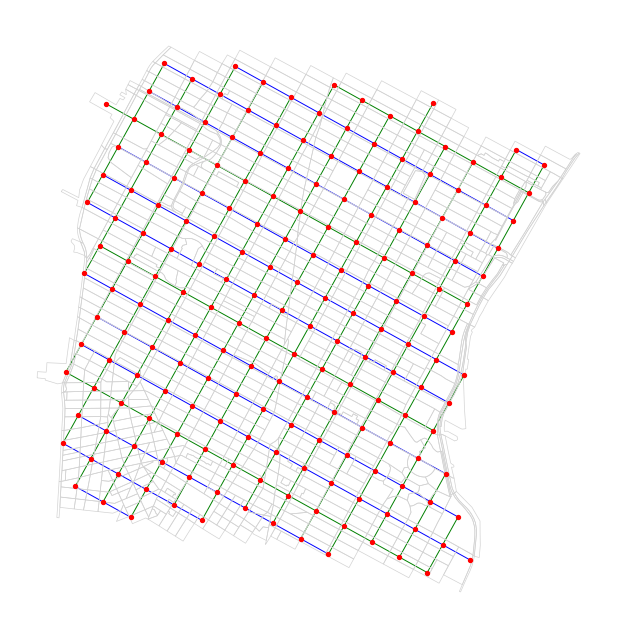

In [6]:
#This code is calculating the sistance ,speed and travel time between these edges 

FAST_SPEED_KPH = 50
SLOW_SPEED_KPH = 25

for start_node, end_node in Graph.edges:
    start_x, start_y = positions[start_node]
    end_x, end_y = positions[end_node]

    distance_m = np.hypot(
        end_x - start_x,
        end_y - start_y,
    )

    is_vertical = start_node[0] == end_node[0]
    is_fourth_horizontal = (
        start_node[1] == end_node[1]
        and start_node[1] % 4 == 0   #Essentially checking if the fourth row is horizontal so it knows whether to assign it as a faster edge weight
    )

    if is_vertical or is_fourth_horizontal:
        speed_kph = FAST_SPEED_KPH
    else:
        speed_kph = SLOW_SPEED_KPH

    speed_mps = speed_kph / 3.6
    travel_time_s = distance_m / speed_mps

    Graph.edges[start_node, end_node]["length_m"] = distance_m
    Graph.edges[start_node, end_node]["speed_kph"] = speed_kph
    Graph.edges[start_node, end_node]["travel_time_s"] = travel_time_s


edge_colors = []

for start_node, end_node in Graph.edges:
    speed = Graph.edges[start_node, end_node]["speed_kph"]

    if speed == FAST_SPEED_KPH:
        edge_colors.append("green")
    else:
        edge_colors.append("blue")

fig, ax = plt.subplots(figsize=(8, 8))

Populations_m.boundary.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5,
)

nx.draw(
    Graph,
    pos=positions,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color=edge_colors,
    width=0.7,
)

ax.set_aspect("equal")
plt.show()

#Green means faster edge
#Blue means slow edge 

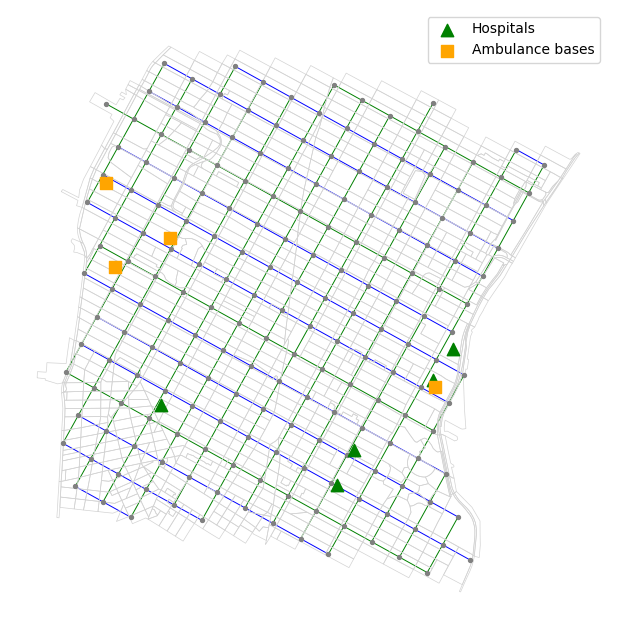

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))

Populations_m.boundary.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5,
)

nx.draw(
    Graph,
    pos=positions,
    ax=ax,
    node_size=8,
    node_color="gray",
    edge_color=edge_colors,
    width=0.7,
)

Hospitals.plot(
    ax=ax,
    color="green",
    marker="^",
    markersize=80,
    label="Hospitals",
    zorder=3,
)

emsstation.plot(
    ax=ax,
    color="orange",
    marker="s",
    markersize=80,
    label="Ambulance bases",
    zorder=3,
)

ax.legend()
ax.set_aspect("equal")
plt.show()

In [8]:

graph_nodes = list(Graph.nodes)

graph_coordinates = []

for node in graph_nodes:
    graph_coordinates.append(positions[node])

graph_coordinates = np.array(graph_coordinates)

node_tree = cKDTree(graph_coordinates)

def find_nearest_node(point):
    point_coordinates = (
        point.x,
        point.y,
    )

    distance, position_index = node_tree.query(point_coordinates)

    nearest_node = graph_nodes[position_index]

    return nearest_node

Hospitals["graph_node"] = Hospitals.geometry.apply(find_nearest_node)
emsstation["graph_node"] = emsstation.geometry.apply(find_nearest_node)
incidents_m["graph_node"] = incidents_m.geometry.apply(find_nearest_node)


def find_fastest_route(start_node, end_node):
    route = nx.shortest_path(
        Graph,
        source=start_node,
        target=end_node,
        weight="travel_time_s",
    )

    total_travel_time_s = float(
        nx.shortest_path_length(
            Graph,
            source=start_node,
            target=end_node,
            weight="travel_time_s",
        )
    )

    return route, total_travel_time_s

def find_fastest_destination(start_node, destination_nodes):
    fastest_node = None
    fastest_route = None
    fastest_time_s = float("inf")

    for destination_node in destination_nodes:
        route, travel_time_s = find_fastest_route(
            start_node,
            destination_node,
        )

        if travel_time_s < fastest_time_s:
            fastest_node = destination_node
            fastest_route = route
            fastest_time_s = travel_time_s

    return fastest_node, fastest_route, fastest_time_s





In [9]:
#Creating ambulance for each EMS station and recording its state
NUMBER_OF_AMBULANCES = 4

station_nodes = emsstation["graph_node"].tolist()

ambulances = []

for ambulance_id in range(NUMBER_OF_AMBULANCES):
    home_node = station_nodes[
        ambulance_id % len(station_nodes)
    ]

    ambulances.append({
        "ambulance_id": ambulance_id,
        "home_node": home_node,
        "current_node": home_node,
        "available": True,
        "return_process": None,
    })

print("Ambulances created:", len(ambulances))

Ambulances created: 4


In [10]:
def find_fastest_available_ambulance(incident_node, ambulances):
    fastest_ambulance = None
    fastest_route = None
    fastest_time_s = float("inf")

    for ambulance in ambulances:
        if ambulance["available"]:
            route, travel_time_s = find_fastest_route(
                ambulance["current_node"],
                incident_node,
            )

            if travel_time_s < fastest_time_s:
                fastest_ambulance = ambulance
                fastest_route = route
                fastest_time_s = travel_time_s

    return fastest_ambulance, fastest_route, fastest_time_s



#This is essentially converting the time of the incident to one continuous simulation clock in minutes 
incidents_sim = incidents_m.copy()

incidents_sim["incident_id"] = incidents_sim.index

incidents_sim["arrival_time_min"] = (
    incidents_sim["day"] * 24 * 60
    + incidents_sim["seconds_since_midnight"] / 60
)

incidents_sim = incidents_sim.sort_values(
    "arrival_time_min"
).reset_index(drop=True)


HIGH_PRIORITY_PROBABILITY = 0.30

priority_generator = np.random.default_rng(123)

incidents_sim["priority"] = np.where(
    priority_generator.random(len(incidents_sim))
    < HIGH_PRIORITY_PROBABILITY,
    "high",
    "low",
)

print(incidents_sim["priority"].value_counts())

#printing the first five elements of the selected columns to focus on
columns_to_show = ["incident_id", "day", "arrival_time_min", "graph_node"]
selected_data = incidents_sim[columns_to_show]
print(
    selected_data.head()
)



priority
low     231
high    117
Name: count, dtype: int64
   incident_id  day  arrival_time_min graph_node
0            0    0          6.827606   (12, 13)
1            1    0         13.334086    (9, 15)
2            2    0         45.048259   (10, 13)
3            3    0         68.218589   (10, 12)
4            4    0         69.939777   (17, 21)


In [11]:


def request_fastest_ambulance(env,incident_node,ambulance_pool,):
    request_time = env.now

    if len(ambulance_pool.items) == 0:
        ambulance = yield ambulance_pool.get()

        route, travel_time_s = find_fastest_route(
            ambulance["current_node"],
            incident_node,
        )

    else:
        selected_ambulance, route, travel_time_s = (
            find_fastest_available_ambulance(
                incident_node,
                ambulance_pool.items,
            )
        )

        ambulance = yield ambulance_pool.get(
            lambda available_ambulance:
                available_ambulance["ambulance_id"]
                == selected_ambulance["ambulance_id"]
        )
    return_process = ambulance.get("return_process")

    if (
        return_process is not None
        and return_process.is_alive
    ):
        return_process.interrupt()
    
    ambulance["return_process"] = None
    
    ambulance["available"] = False

    waiting_time_min = env.now - request_time

    return (
        ambulance,
        route,
        travel_time_s,
        waiting_time_min,
    )

#Function for ambulance returning home while its available 
def return_home_while_available(env, ambulance):
    try:
        return_route, _ = find_fastest_route(
            ambulance["current_node"],
            ambulance["home_node"],
        )

        for start_node, end_node in zip(
            return_route[:-1],
            return_route[1:],
        ):
            edge_travel_time_s = Graph.edges[
                start_node,
                end_node,
            ]["travel_time_s"]

            edge_travel_time_min = (
                edge_travel_time_s / 60
            )

            yield env.timeout(edge_travel_time_min)

            # Ambulance has reached the next graph node
            ambulance["current_node"] = end_node

    except simpy.Interrupt:
        # A new incident selected this ambulance
        pass

    finally:
        ambulance["return_process"] = None

Incidents completed: 348
Final simulation time: 14410.473879613637
(348, 12)
   incident_id priority  ambulance_id  entered_queue  waiting_time_min  \
0            0      low             1          False            0.0000   
1            1     high             0          False            0.0000   
2            2     high             3          False            0.0000   
3            3     high             2          False            0.0000   
4            4     high             0           True            3.6989   

   response_time_min  on_scene_time_min  hospital_travel_time_min  \
0             1.5000          21.523585                       1.5   
1             0.6000          14.800079                       2.4   
2             2.4000          10.244824                       1.5   
3             2.7000          20.639202                       1.2   
4             9.0989          18.418787                       2.1   

   turnaround_time_min  return_travel_time_min  busy_time_min h

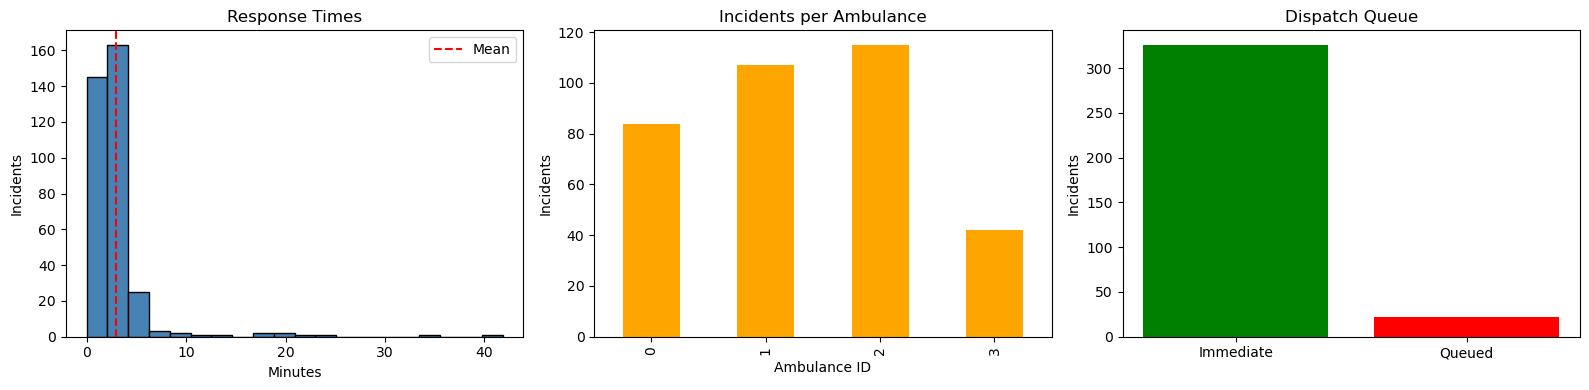

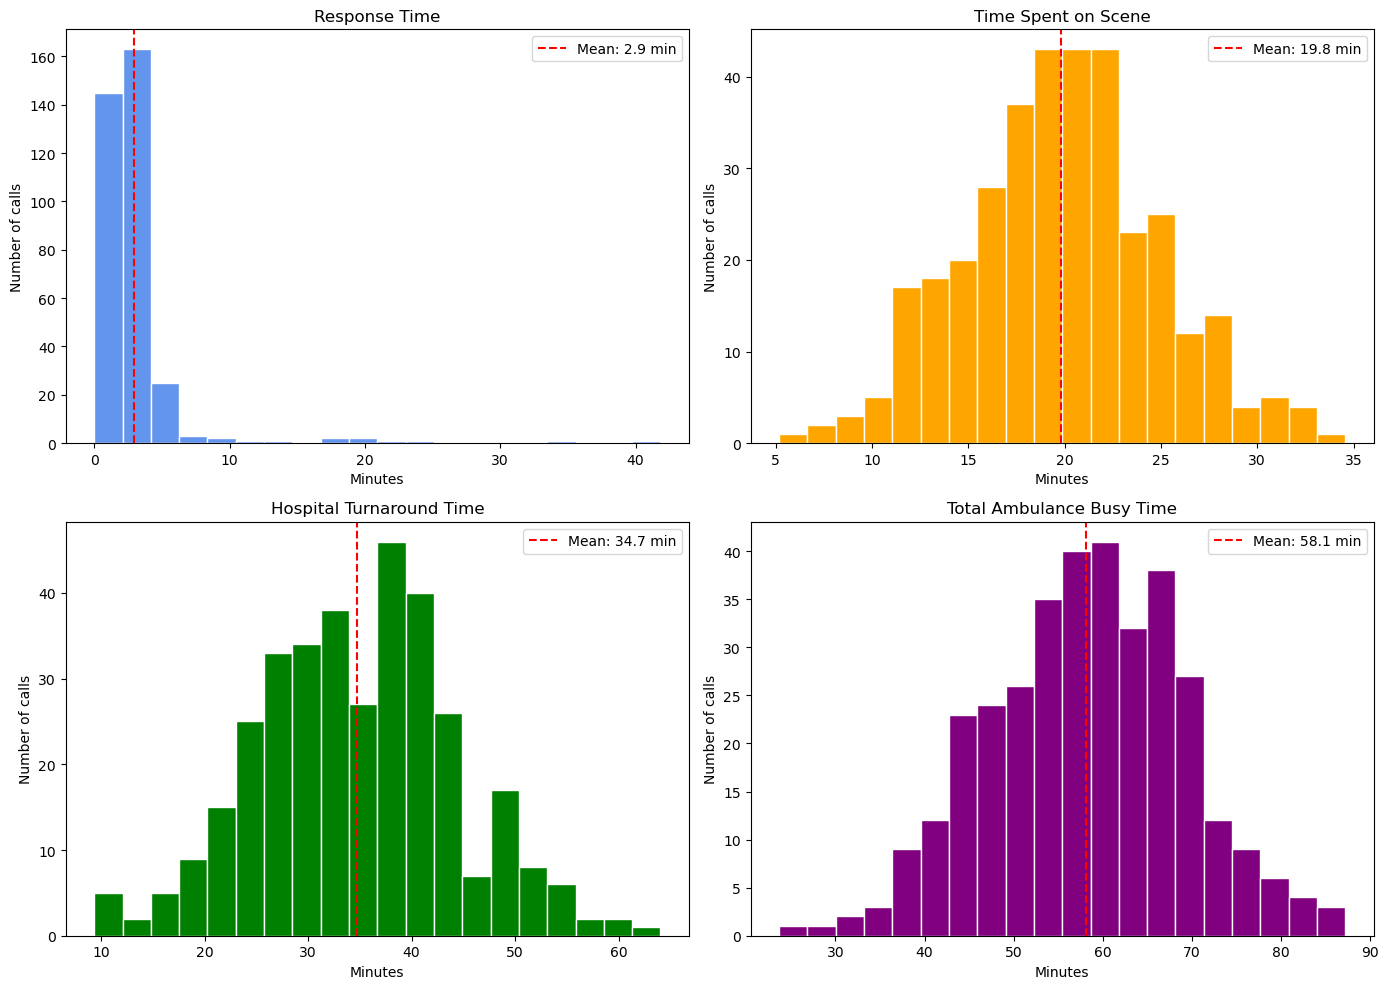

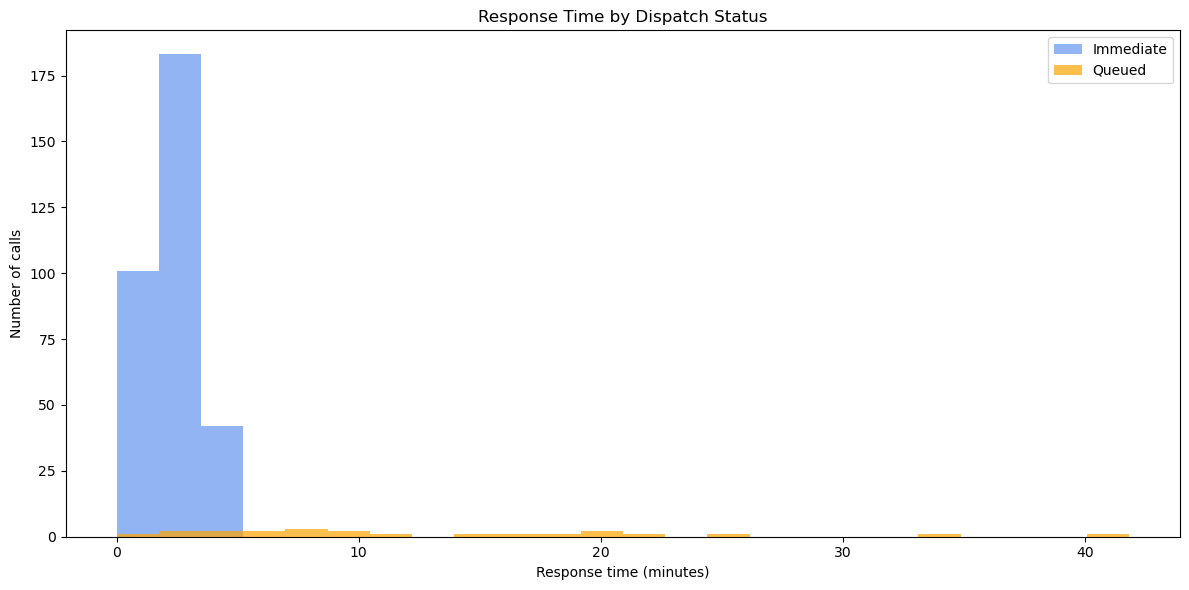

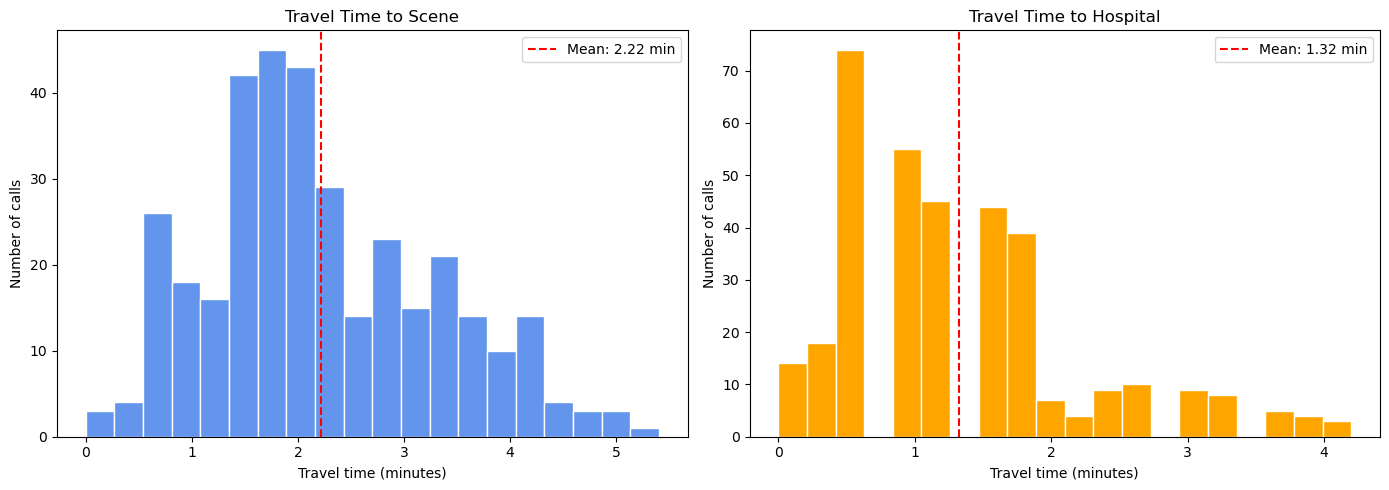

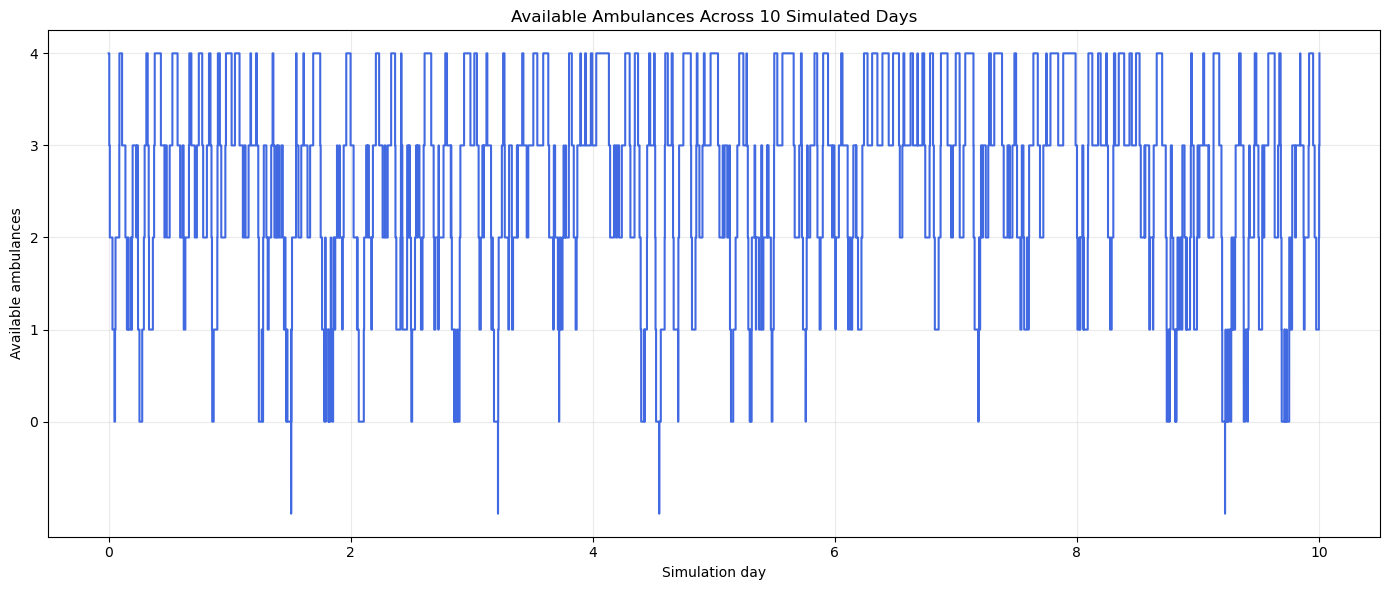

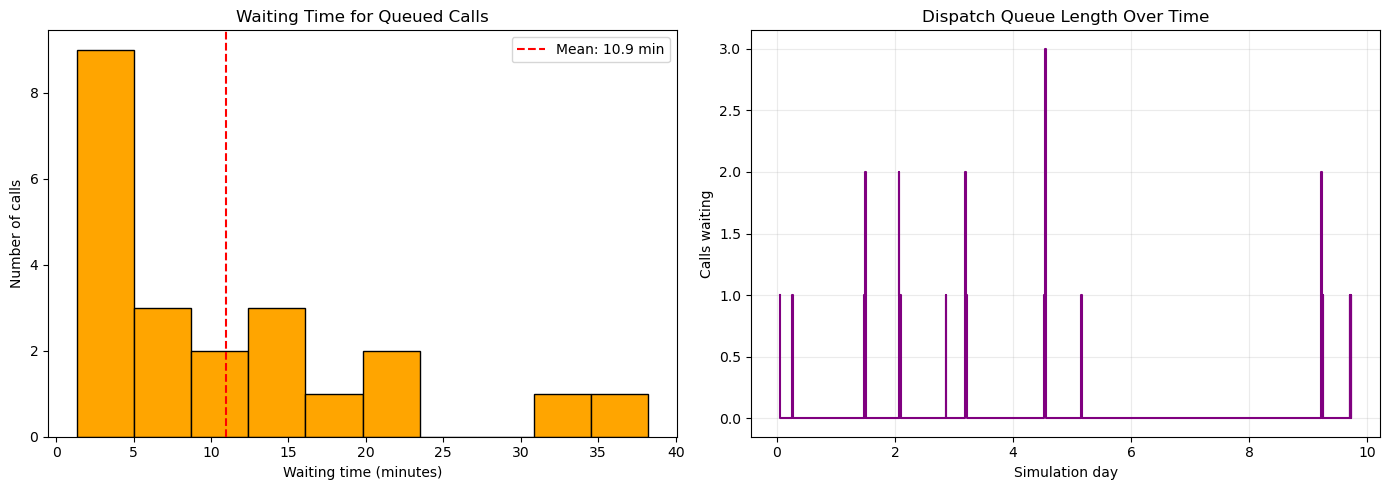

Calls that waited: 22
Average wait among queued calls: 10.94214211016531
Longest wait: 38.23268041622032
Maximum queue length: 3


In [12]:
#Defining timing assumptions
random_generator = np.random.default_rng(42)

hospital_nodes = list(Hospitals["graph_node"])

ON_SCENE_MEAN_MIN = 20
ON_SCENE_SD_MIN = 5

TURNAROUND_MEAN_MIN = 35
TURNAROUND_SD_MIN = 10

#Creation of the incident process

def handle_incident(env,incident,ambulance_pool,ambulance_slots,simulation_results,):    
    incident_node = incident["graph_node"]
    incident_priority = incident["priority"]

    # Lower numbers have higher priority in SimPy
    if incident_priority == "high":
        queue_priority = 0
    else:
        queue_priority = 1

    queue_start_time = env.now

    ambulance_request = ambulance_slots.request(
        priority=queue_priority
    )

    yield ambulance_request

    waiting_time_min = env.now - queue_start_time
    entered_queue = waiting_time_min > 0

    (
        ambulance,
        response_route,
        response_travel_time_s,
        _,
    ) = yield env.process(
        request_fastest_ambulance(
            env,
            incident_node,
            ambulance_pool,
        )
    )

    response_travel_time_min = response_travel_time_s / 60

    yield env.timeout(response_travel_time_min)

    ambulance["current_node"] = incident_node

    on_scene_time_min = max(1,random_generator.normal(ON_SCENE_MEAN_MIN,ON_SCENE_SD_MIN,),)

    yield env.timeout(on_scene_time_min)

    (
        hospital_node,
        hospital_route,
        hospital_travel_time_s,
    ) = find_fastest_destination(
        incident_node,
        hospital_nodes,
    )

    hospital_travel_time_min = hospital_travel_time_s / 60

    yield env.timeout(hospital_travel_time_min)

    ambulance["current_node"] = hospital_node

    turnaround_time_min = max(
        1,
        random_generator.normal(
            TURNAROUND_MEAN_MIN,
            TURNAROUND_SD_MIN,
        ),
    )

    yield env.timeout(turnaround_time_min)

    # Ambulance is now available at the hospital
    return_travel_time_min = 0.0
    
    ambulance["available"] = True
    
    yield ambulance_pool.put(ambulance)

    # Travel home while remaining available
    ambulance["return_process"] = env.process(
        return_home_while_available(
            env,
            ambulance,
        )
    )
    
    response_time_min = (
        waiting_time_min
        + response_travel_time_min
    )
    
    busy_time_min = (
        response_travel_time_min
        + on_scene_time_min
        + hospital_travel_time_min
        + turnaround_time_min
    )

    simulation_results.append(
        {
            "incident_id": incident["incident_id"],
            "priority": incident_priority,
            "ambulance_id": ambulance["ambulance_id"],
            "entered_queue": entered_queue,
            "waiting_time_min": waiting_time_min,
            "response_time_min": response_time_min,
            "on_scene_time_min": on_scene_time_min,
            "hospital_travel_time_min": hospital_travel_time_min,
            "turnaround_time_min": turnaround_time_min,
            "return_travel_time_min": return_travel_time_min,
            "busy_time_min": busy_time_min,
            "hospital_node": hospital_node,
        }
    )
    ambulance_slots.release(ambulance_request)

#This process introduces incidents at their scheduled times 
def generate_incident_arrivals(
    env,
    incidents_sim,
    ambulance_pool,
    ambulance_slots,
    simulation_results,
):
    for _, incident in incidents_sim.iterrows():
        time_until_arrival = (
            incident["arrival_time_min"] - env.now
        )

        if time_until_arrival > 0:
            yield env.timeout(time_until_arrival)

        env.process(
            handle_incident(
                env,
                incident,
                ambulance_pool,
                ambulance_slots,
                simulation_results,
            )
        )


#Creating new environment for fresh simpy run 
env = simpy.Environment()

ambulance_pool = simpy.FilterStore(
    env,
    capacity=len(ambulances),
)
ambulance_slots = simpy.PriorityResource(
    env,
    capacity=len(ambulances),
)

for ambulance in ambulances:
    ambulance["available"] = True
    ambulance["current_node"] = ambulance["home_node"]
    ambulance["return_process"] = None 
    ambulance_pool.put(ambulance)

simulation_results = []

random_generator = np.random.default_rng(42)

env.process(
    generate_incident_arrivals(
        env,
        incidents_sim,
        ambulance_pool,
        ambulance_slots,
        simulation_results,
    )
)

env.run()

print("Incidents completed:", len(simulation_results))
print("Final simulation time:", env.now)

#Converting results from new simpy run into a dataframe 
results_df = pd.DataFrame(simulation_results)

results_df = results_df.sort_values(
    "incident_id"
).reset_index(drop=True)

print(results_df.shape)
print(results_df.head())


#Essentially calculating the performance metrics that hav been generated and printng it out too 
results_df["response_travel_time_min"] = (
    results_df["response_time_min"]
    - results_df["waiting_time_min"]
)

total_incidents = len(results_df)

queued_incidents = int(
    results_df["entered_queue"].sum()
)

queue_percentage = (
    queued_incidents / total_incidents * 100
)

print("Total incidents:", total_incidents)
print("Incidents that entered queue:", queued_incidents)
print("Queue percentage:", queue_percentage)

print(
    "Average waiting time:",
    results_df["waiting_time_min"].mean(),
)

print(
    "Average response time:",
    results_df["response_time_min"].mean(),
)

print(
    "Average on-scene time:",
    results_df["on_scene_time_min"].mean(),
)

print(
    "Average hospital travel time:",
    results_df["hospital_travel_time_min"].mean(),
)

print(
    "Average turnaround time:",
    results_df["turnaround_time_min"].mean(),
)

print(
    "Average ambulance busy time:",
    results_df["busy_time_min"].mean(),
)
print(
    results_df.groupby("priority")[
        ["waiting_time_min", "response_time_min"]
    ].mean()
)




















#Graphing code 
#Now i am going to try to create charts that represent these metrics thta I have generated

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4),
)

# Response-time distribution
axes[0].hist(
    results_df["response_time_min"],
    bins=20,
    color="steelblue",
    edgecolor="black",
)

axes[0].axvline(
    results_df["response_time_min"].mean(),
    color="red",
    linestyle="--",
    label="Mean",
)

axes[0].set_title("Response Times")
axes[0].set_xlabel("Minutes")
axes[0].set_ylabel("Incidents")
axes[0].legend()

# Incidents handled by each ambulance
ambulance_counts = (
    results_df["ambulance_id"]
    .value_counts()
    .sort_index()
)

ambulance_counts.plot(
    kind="bar",
    ax=axes[1],
    color="orange",
)

axes[1].set_title("Incidents per Ambulance")
axes[1].set_xlabel("Ambulance ID")
axes[1].set_ylabel("Incidents")

# Queued versus immediately served
queue_counts = (
    results_df["entered_queue"]
    .value_counts()
    .reindex([False, True], fill_value=0)
)

axes[2].bar(
    ["Immediate", "Queued"],
    queue_counts.values,
    color=["green", "red"],
)

axes[2].set_title("Dispatch Queue")
axes[2].set_ylabel("Incidents")

plt.tight_layout()
plt.show()


#Four Timing Distributions 
plot_information = [
    (
        "response_time_min",
        "Response Time",
        "cornflowerblue",
    ),
    (
        "on_scene_time_min",
        "Time Spent on Scene",
        "orange",
    ),
    (
        "turnaround_time_min",
        "Hospital Turnaround Time",
        "green",
    ),
    (
        "busy_time_min",
        "Total Ambulance Busy Time",
        "purple",
    ),
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)

for ax, column, title, color in [
    (axes[0, 0], *plot_information[0]),
    (axes[0, 1], *plot_information[1]),
    (axes[1, 0], *plot_information[2]),
    (axes[1, 1], *plot_information[3]),
]:
    mean_value = results_df[column].mean()

    ax.hist(
        results_df[column],
        bins=20,
        color=color,
        edgecolor="white",
    )

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        label=f"Mean: {mean_value:.1f} min",
    )

    ax.set_title(title)
    ax.set_xlabel("Minutes")
    ax.set_ylabel("Number of calls")
    ax.legend()

plt.tight_layout()
plt.show()


#Response Time by Dispatch status graph 
immediate_responses = results_df.loc[
    results_df["entered_queue"] == False,
    "response_time_min",
]

queued_responses = results_df.loc[
    results_df["entered_queue"] == True,
    "response_time_min",
]

response_bins = np.linspace(
    results_df["response_time_min"].min(),
    results_df["response_time_min"].max(),
    25,
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    immediate_responses,
    bins=response_bins,
    alpha=0.7,
    label="Immediate",
    color="cornflowerblue",
)

ax.hist(
    queued_responses,
    bins=response_bins,
    alpha=0.7,
    label="Queued",
    color="orange",
)

ax.set_title("Response Time by Dispatch Status")
ax.set_xlabel("Response time (minutes)")
ax.set_ylabel("Number of calls")
ax.legend()

plt.tight_layout()
plt.show()

#Travel time distributions graph 
results_df["response_travel_time_min"] = (
    results_df["response_time_min"]
    - results_df["waiting_time_min"]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

travel_plots = [
    (
        axes[0],
        "response_travel_time_min",
        "Travel Time to Scene",
        "cornflowerblue",
    ),
    (
        axes[1],
        "hospital_travel_time_min",
        "Travel Time to Hospital",
        "orange",
    ),
]

for ax, column, title, color in travel_plots:
    mean_value = results_df[column].mean()

    ax.hist(
        results_df[column],
        bins=20,
        color=color,
        edgecolor="white",
    )

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        label=f"Mean: {mean_value:.2f} min",
    )

    ax.set_title(title)
    ax.set_xlabel("Travel time (minutes)")
    ax.set_ylabel("Number of calls")
    ax.legend()

plt.tight_layout()
plt.show()



#Available ambulances over time graph 
availability_source = results_df.merge(
    incidents_sim[
        ["incident_id", "arrival_time_min"]
    ],
    on="incident_id",
    how="left",
)

availability_events = []

for _, incident_result in availability_source.iterrows():
    dispatch_time = (
        incident_result["arrival_time_min"]
        + incident_result["waiting_time_min"]
    )

    return_time = (
        dispatch_time
        + incident_result["busy_time_min"]
    )

    availability_events.append(
        {
            "time_min": dispatch_time,
            "change": -1,
        }
    )

    availability_events.append(
        {
            "time_min": return_time,
            "change": 1,
        }
    )

availability_timeline = pd.DataFrame(
    availability_events
)

availability_timeline = (
    availability_timeline
    .groupby("time_min", as_index=False)["change"]
    .sum()
    .sort_values("time_min")
)

total_ambulances = len(ambulances)

availability_timeline["available_ambulances"] = (
    total_ambulances
    + availability_timeline["change"].cumsum()
)

initial_state = pd.DataFrame(
    {
        "time_min": [0],
        "change": [0],
        "available_ambulances": [total_ambulances],
    }
)

availability_timeline = pd.concat(
    [initial_state, availability_timeline],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(14, 6))

ax.step(
    availability_timeline["time_min"] / 1440,
    availability_timeline["available_ambulances"],
    where="post",
    color="royalblue",
)

ax.set_title(
    "Available Ambulances Across 10 Simulated Days"
)
ax.set_xlabel("Simulation day")
ax.set_ylabel("Available ambulances")
ax.set_yticks(range(total_ambulances + 1))
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()






#Code to show how long calls in queue waited and how long the queue got 
# Keep only incidents that had to wait
# Keep only incidents that entered the queue
queued_calls = results_df.loc[
    results_df["entered_queue"],
    ["incident_id", "waiting_time_min"],
].copy()

# Add incident arrival times
queued_calls = queued_calls.merge(
    incidents_sim[["incident_id", "arrival_time_min"]],
    on="incident_id",
)

# Calculate when each call left the queue
queued_calls["dispatch_time_min"] = (
    queued_calls["arrival_time_min"]
    + queued_calls["waiting_time_min"]
)

number_queued = len(queued_calls)

mean_queued_wait = (
    queued_calls["waiting_time_min"].mean()
    if number_queued > 0
    else 0.0
)

longest_wait = (
    queued_calls["waiting_time_min"].max()
    if number_queued > 0
    else 0.0
)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Graph 1: Waiting-time distribution
if number_queued > 0:
    axes[0].hist(
        queued_calls["waiting_time_min"],
        bins=10,
        color="orange",
        edgecolor="black",
    )

    axes[0].axvline(
        mean_queued_wait,
        color="red",
        linestyle="--",
        label=f"Mean: {mean_queued_wait:.1f} min",
    )

    axes[0].legend()

else:
    axes[0].text(
        0.5,
        0.5,
        "No calls entered the queue",
        ha="center",
        va="center",
        transform=axes[0].transAxes,
    )

axes[0].set_title("Waiting Time for Queued Calls")
axes[0].set_xlabel("Waiting time (minutes)")
axes[0].set_ylabel("Number of calls")


# Graph 2: Queue length over time
if number_queued > 0:
    queue_events = pd.concat(
        [
            pd.DataFrame({
                "time_min": queued_calls["arrival_time_min"],
                "change": 1,
            }),
            pd.DataFrame({
                "time_min": queued_calls["dispatch_time_min"],
                "change": -1,
            }),
        ],
        ignore_index=True,
    )

    queue_history = (
        queue_events.groupby("time_min", as_index=False)["change"]
        .sum()
        .sort_values("time_min")
    )

    queue_history["queue_length"] = (
        queue_history["change"].cumsum()
    )

    max_queue_length = int(
        queue_history["queue_length"].max()
    )

    axes[1].step(
        queue_history["time_min"] / (24 * 60),
        queue_history["queue_length"],
        where="post",
        color="purple",
    )

else:
    max_queue_length = 0

    axes[1].plot(
        [0, env.now / (24 * 60)],
        [0, 0],
        color="purple",
    )

    axes[1].set_ylim(-0.1, 1)

axes[1].set_title("Dispatch Queue Length Over Time")
axes[1].set_xlabel("Simulation day")
axes[1].set_ylabel("Calls waiting")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


print("Calls that waited:", number_queued)
print("Average wait among queued calls:", mean_queued_wait)
print("Longest wait:", longest_wait)
print("Maximum queue length:", max_queue_length)